# NOAA AIS 2025 — TASK-RAW-02 & TASK 03
**Đầu vào duy nhất: `noaa_ais_2025_raw_labeled.parquet`.**

Notebook chia thành: **0. Chuẩn bị dùng chung → A. RAW2 → B. Task 03 → C. Xuất kết quả**.

## Chạy trên Kaggle
1. Import notebook này, thêm dataset `kienvo134/noaa-ais-2025-full-year-tin-x-l-nn-tng`.
2. Chọn CPU. Chạy các cell từ trên xuống. Không cần GPU; không tự cài package qua Internet.
3. Mặc định quét toàn bộ raw theo batch, lấy mẫu đều tối đa 320.000 dòng để thử nghiệm.
4. Các kết quả nằm tại `/kaggle/working/task03_raw02`; cuối notebook có file ZIP để tải.
5. Sau khi hoàn thành, Save Version để giữ notebook và outputs.

## Phạm vi kết luận
- Raw labeled đã qua chọn tàu/ghép nhãn, không phải toàn bộ AIS nguồn.
- EDA đếm và moments: toàn bộ raw nếu `MAX_BATCHES=None`. Phân vị/skewness: **ước lượng trên mẫu**.
- Bộ lọc, mask-and-recover, Pearson và LightGBM: **thử nghiệm trên mẫu lấy từ raw**.
- Không đọc bản nền tảng/ML-ready; không tái chạy Pass 1; không có `atd_prev`; không tái tạo chính xác số dòng sạch trong tài liệu.
- Không suy ra mọi SOG=0/status neo là lỗi. Không khẳng định hiệu quả mô hình nếu chưa chạy.
- Q4 không dùng để lựa chọn đặc trưng hay điều chỉnh phương pháp. Notebook không đánh giá cuối cùng trên Q4.
- Khoảng cách tới bến ghép từ tương lai chỉ là đầu vào hợp lệ khi bến đích được biết độc lập lúc dự báo. Cờ sử dụng biến này mặc định tắt.

**Các nguồn yêu cầu:** KeHoach_BoSung_NoiDung(4).md; HuongDan_DieuChinh_Dataset_Tho(2).md; Quy_trinh_3_phien_ban_dataset(4).md. Các số liệu trong tài liệu không được hard-code làm kết quả đo.


In [1]:
from pathlib import Path
import json, gc, time, zipfile, importlib.util, platform
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, FileLink

required_packages = ['pyarrow', 'lightgbm']
missing_packages = [p for p in required_packages if importlib.util.find_spec(p) is None]
if missing_packages:
    raise ImportError('Môi trường thiếu package: ' + ', '.join(missing_packages)
                      + '. Hãy cài vào môi trường rồi chạy lại. Notebook không tự dùng Internet.')
import pyarrow.parquet as pq
import lightgbm as lgb

ROOT = Path('/kaggle/input/noaa-ais-2025-full-year-tin-x-l-nn-tng')
OUT = Path('/kaggle/working/task03_raw02')
BATCH_SIZE = 250_000
SAMPLE_SIZE = 320_000
SEED = 42
MAX_BATCHES = None       # None = toàn bộ; đặt 10 để chạy thử, KHÔNG báo cáo là toàn năm
REUSE_SCAN_CACHE = True  # Cache chỉ dùng khi input/config khớp và scan trước hoàn tất
KNOWN_DESTINATION_AT_PREDICTION = False
RUN_ASYMMETRIC_EXPERIMENT = True
N_ESTIMATORS = 800
N_JOBS = 4

OUT.mkdir(parents=True, exist_ok=True)
RAW2 = OUT / 'RAW2'
TASK03 = OUT / 'TASK03'
COMMON = OUT / 'COMMON'
for folder in [RAW2, TASK03, COMMON]: folder.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
print('Python:', platform.python_version(), '| LightGBM:', lgb.__version__)


Python: 3.13.15 | LightGBM: 4.6.0


In [2]:
raw_path = ROOT / 'noaa_ais_2025_raw_labeled.parquet'
if not raw_path.exists():
    matches = list(ROOT.rglob('noaa_ais_2025_raw_labeled.parquet')) if ROOT.exists() else []
    if not matches:
        matches = list(Path('/kaggle/input').rglob('noaa_ais_2025_raw_labeled.parquet'))
    if len(matches) != 1:
        raise FileNotFoundError(f'Cần đúng một raw labeled. Tìm thấy: {matches}. Sửa ROOT.')
    raw_path = matches[0]
assert raw_path.name == 'noaa_ais_2025_raw_labeled.parquet'
pf = pq.ParquetFile(raw_path)
COLS = ['mmsi','trip_id','base_date_time','longitude','latitude','sog','cog',
        'heading','status','vessel_type','length','width','draft','cargo',
        'berth_lon','berth_lat','ata_time','Target_Hours']
assert set(COLS).issubset(pf.schema_arrow.names), 'Schema raw thiếu cột yêu cầu'
print('Đầu vào duy nhất:', raw_path)
print('Số dòng metadata:', f'{pf.metadata.num_rows:,}')
print(pf.schema_arrow)
(COMMON / 'schema.txt').write_text(str(pf.schema_arrow), encoding='utf-8')

def save_table(df, path):
    df.to_csv(path, index=False, encoding='utf-8-sig')

def save_fig(fig, path):
    fig.tight_layout()
    fig.savefig(path, dpi=220, bbox_inches='tight')
    plt.show()
    plt.close(fig)


Đầu vào duy nhất: /kaggle/input/datasets/kienvo134/noaa-ais-2025-full-year-tin-x-l-nn-tng/noaa_ais_2025_raw_labeled.parquet
Số dòng metadata: 320,776,922
mmsi: int64
trip_id: string
base_date_time: timestamp[us]
longitude: float
latitude: float
sog: float
cog: float
heading: float
status: float
vessel_type: float
length: float
width: float
draft: float
cargo: float
berth_lon: float
berth_lat: float
ata_time: timestamp[us]
Target_Hours: float


# A. TASK-RAW-02 — Mục 5.4 và 6.1–6.4
## A1. Quét raw theo batch, EDA toàn bộ và lấy mẫu đều
Lấy mẫu bằng vị trí dòng chọn ngẫu nhiên không hoàn lại, không cân bằng lại target. RAM chỉ chứa một batch và mẫu nhỏ. Cache chỉ được đánh dấu hoàn tất sau khi scan xong; nếu kernel bị dừng giữa scan, chạy lại từ đầu.

`N` thống kê chỉ gồm giá trị hữu hạn; NaN/±Inf được đếm riêng. Std dùng mẫu (`ddof=1`). Các histogram có đếm ngoài miền trong bảng audit. Khi chạy thử giới hạn batch, mẫu chỉ đại diện phần đã quét.


In [3]:
scan_config = dict(path=str(raw_path), file_size=raw_path.stat().st_size,
                   mtime_ns=raw_path.stat().st_mtime_ns, rows=pf.metadata.num_rows,
                   batch_size=BATCH_SIZE, sample_size=SAMPLE_SIZE, seed=SEED,
                   max_batches=MAX_BATCHES, version=2)
cache_meta = COMMON / 'scan_complete.json'
cache_files = ['raw_sample.parquet','audit.csv','moments.csv','vessel.csv','status.csv','histograms.npz']
use_cache = (REUSE_SCAN_CACHE and cache_meta.exists()
             and all((COMMON / p).exists() for p in cache_files)
             and json.loads(cache_meta.read_text()) == scan_config)

sog_edges = np.linspace(0, 110, 221)
y_edges = np.linspace(0, 168, 85)
stat_cols = ['Target_Hours','sog','cog','draft','length','width']

def num(d, c):
    return pd.to_numeric(d[c], errors='coerce').to_numpy(dtype=float, na_value=np.nan)

if use_cache:
    sample = pd.read_parquet(COMMON / 'raw_sample.parquet')
    audit = pd.read_csv(COMMON / 'audit.csv')
    moments = pd.read_csv(COMMON / 'moments.csv')
    vessel_table = pd.read_csv(COMMON / 'vessel.csv', dtype={'value':str})
    status_table = pd.read_csv(COMMON / 'status.csv', dtype={'value':str})
    h = np.load(COMMON / 'histograms.npz')
    hist_sog, hist_target = h['sog'], h['target']
    print('Đã dùng cache hoàn tất với config khớp.')
else:
    cache_meta.unlink(missing_ok=True)
    rng = np.random.default_rng(SEED)
    total = pf.metadata.num_rows
    positions = np.sort(rng.choice(total, size=min(SAMPLE_SIZE,total), replace=False))
    counts, vessels, statuses = Counter(), Counter(), Counter()
    states = {c:dict(n=0, mean=0., m2=0., min=np.inf, max=-np.inf) for c in stat_cols}
    hist_sog = np.zeros(len(sog_edges)-1, dtype=np.int64)
    hist_target = np.zeros(len(y_edges)-1, dtype=np.int64)
    parts, offset, started = [], 0, time.time()
    for i, batch in enumerate(pf.iter_batches(batch_size=BATCH_SIZE, columns=COLS)):
        if MAX_BATCHES is not None and i >= MAX_BATCHES: break
        d = batch.to_pandas()
        n = len(d)
        counts['N_raw'] += n
        for c in stat_cols:
            x = num(d,c); x = x[np.isfinite(x)]
            if len(x):
                st = states[c]; bn=len(x); bm=float(x.mean()); bm2=float(((x-bm)**2).sum())
                delta=bm-st['mean']; nn=st['n']+bn
                st['m2'] += bm2 + delta*delta*st['n']*bn/nn
                st['mean'] += delta*bn/nn
                st['n']=nn; st['min']=min(st['min'],float(x.min())); st['max']=max(st['max'],float(x.max()))
        s = num(d,'sog'); fs=np.isfinite(s)
        groups = {'SOG_nonfinite':~fs,'SOG_negative':fs&(s<0),'SOG_zero':fs&(s==0),
                  'SOG_0_to_1':fs&(s>0)&(s<1),'SOG_1_to_40':fs&(s>=1)&(s<=40),
                  'SOG_over_40':fs&(s>40),'SOG_over_110':fs&(s>110)}
        y=num(d,'Target_Hours'); fy=np.isfinite(y)
        groups.update({'Target_nonfinite':~fy,'Target_negative':fy&(y<0),
                       'Target_zero':fy&(y==0),'Target_0_to_168':fy&(y>0)&(y<=168),
                       'Target_over_168':fy&(y>168)})
        for c in ['length','width','draft']:
            x=num(d,c); f=np.isfinite(x)
            groups[c+'_nonfinite']=~f
            groups[c+'_invalid_finite']=f&((x<=0)|((x>25.5) if c=='draft' else False))
        for k,v in groups.items(): counts[k] += int(v.sum())
        hist_sog += np.histogram(s[fs],bins=sog_edges)[0]
        hist_target += np.histogram(y[fy&(y>=0)&(y<=168)],bins=y_edges)[0]
        for c, counter in [('vessel_type',vessels),('status',statuses)]:
            v=pd.to_numeric(d[c],errors='coerce'); v=v.where(np.isfinite(v))
            labels=v.astype('string').fillna('Missing')
            counter.update(labels.value_counts().to_dict())
        lo=np.searchsorted(positions,offset); hi=np.searchsorted(positions,offset+n)
        if hi>lo: parts.append(d.iloc[positions[lo:hi]-offset].copy())
        offset += n
        if (i+1)%50==0: print(f'Batch {i+1:,} | {offset:,} dòng | {(time.time()-started)/60:.1f} phút')
        del d,batch
    if not parts: raise ValueError('Không có mẫu; tăng MAX_BATCHES hoặc SAMPLE_SIZE.')
    sample=pd.concat(parts,ignore_index=True); del parts
    if MAX_BATCHES is None: assert offset==total
    audit=pd.DataFrame([{'metric':k,'count':int(v)} for k,v in counts.items()])
    audit['pct_of_scanned_raw']=100*audit['count']/offset
    moments=pd.DataFrame([dict(variable=c,N=st['n'],Mean=st['mean'] if st['n'] else np.nan,
               Std=np.sqrt(st['m2']/(st['n']-1)) if st['n']>1 else np.nan,
               Min=st['min'] if st['n'] else np.nan,Max=st['max'] if st['n'] else np.nan)
               for c,st in states.items()])
    def tab(counter):
        t=pd.DataFrame(list(counter.items()),columns=['value','count']).sort_values('count',ascending=False)
        t['pct_of_scanned_raw']=100*t['count']/offset
        return t
    vessel_table,status_table=tab(vessels),tab(statuses)
    sample.to_parquet(COMMON/'raw_sample.parquet',index=False)
    for df,name in [(audit,'audit.csv'),(moments,'moments.csv'),(vessel_table,'vessel.csv'),(status_table,'status.csv')]:
        save_table(df,COMMON/name)
    np.savez(COMMON/'histograms.npz',sog=hist_sog,target=hist_target)
    cache_meta.write_text(json.dumps(scan_config,ensure_ascii=False,indent=2))
    gc.collect()
SCOPE = 'Toàn bộ raw' if MAX_BATCHES is None else 'CHẠY THỬ: phần raw đã quét'
print(SCOPE, '| Mẫu:',len(sample))
display(audit)
display(moments)


Batch 50 | 12,500,000 dòng | 0.5 phút
Batch 100 | 25,000,000 dòng | 1.0 phút
Batch 150 | 37,500,000 dòng | 1.5 phút
Batch 200 | 50,000,000 dòng | 2.1 phút
Batch 250 | 62,500,000 dòng | 2.6 phút
Batch 300 | 75,000,000 dòng | 3.1 phút
Batch 350 | 87,500,000 dòng | 3.6 phút
Batch 400 | 100,000,000 dòng | 4.1 phút
Batch 450 | 112,500,000 dòng | 4.6 phút
Batch 500 | 125,000,000 dòng | 5.1 phút
Batch 550 | 137,500,000 dòng | 5.6 phút
Batch 600 | 150,000,000 dòng | 6.1 phút
Batch 650 | 162,500,000 dòng | 6.6 phút
Batch 700 | 175,000,000 dòng | 7.1 phút
Batch 750 | 187,500,000 dòng | 7.6 phút
Batch 800 | 200,000,000 dòng | 8.2 phút
Batch 850 | 212,500,000 dòng | 8.7 phút
Batch 900 | 225,000,000 dòng | 9.2 phút
Batch 950 | 237,500,000 dòng | 9.7 phút
Batch 1,000 | 250,000,000 dòng | 10.2 phút
Batch 1,050 | 262,500,000 dòng | 10.8 phút
Batch 1,100 | 275,000,000 dòng | 11.3 phút
Batch 1,150 | 287,500,000 dòng | 11.8 phút
Batch 1,200 | 300,000,000 dòng | 12.3 phút
Batch 1,250 | 312,500,000 dòng | 

,metric,count,pct_of_scanned_raw
0,N_raw,320776922,100.000000
1,SOG_nonfinite,299345,0.093319
2,SOG_negative,0,0.000000
3,SOG_zero,119366838,37.211791
4,SOG_0_to_1,37236779,11.608310
5,SOG_1_to_40,163873321,51.086381
6,SOG_over_40,639,0.000199
7,SOG_over_110,0,0.000000
8,Target_nonfinite,38453008,11.987461
9,Target_negative,0,0.000000


,variable,N,Mean,Std,Min,Max
0,Target_Hours,282323914,436.590556,887.360077,0.0,8723.911133
1,sog,320477577,5.691375,6.244542,0.0,99.900002
2,cog,317652172,185.409956,103.424948,0.0,359.899994
3,draft,312893244,8.616703,2.904418,0.1,24.299999
4,length,319269108,197.441388,75.355847,1.0,419.000000
5,width,316826290,30.696792,10.141872,2.0,61.000000


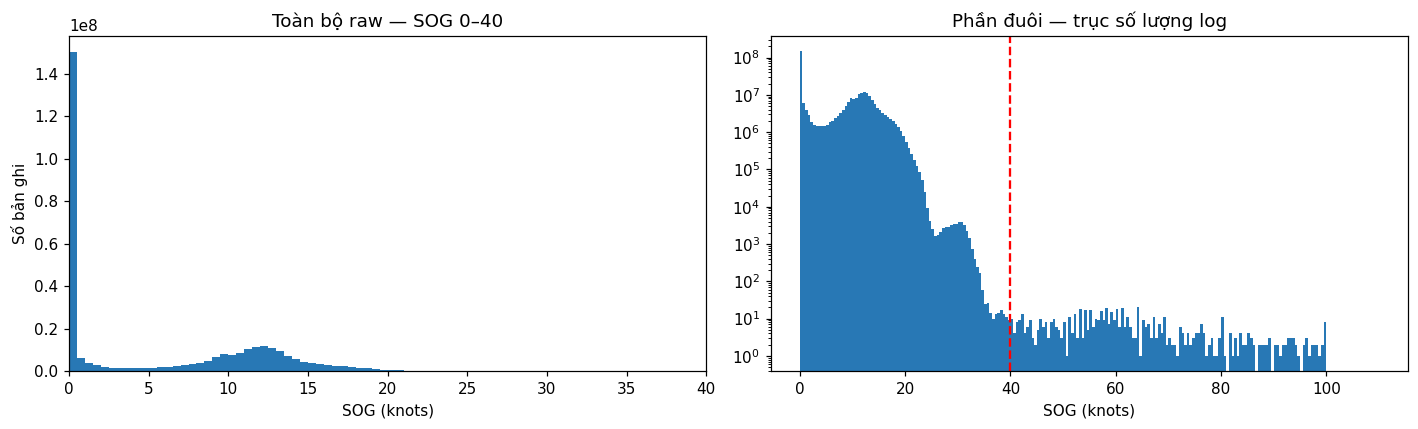

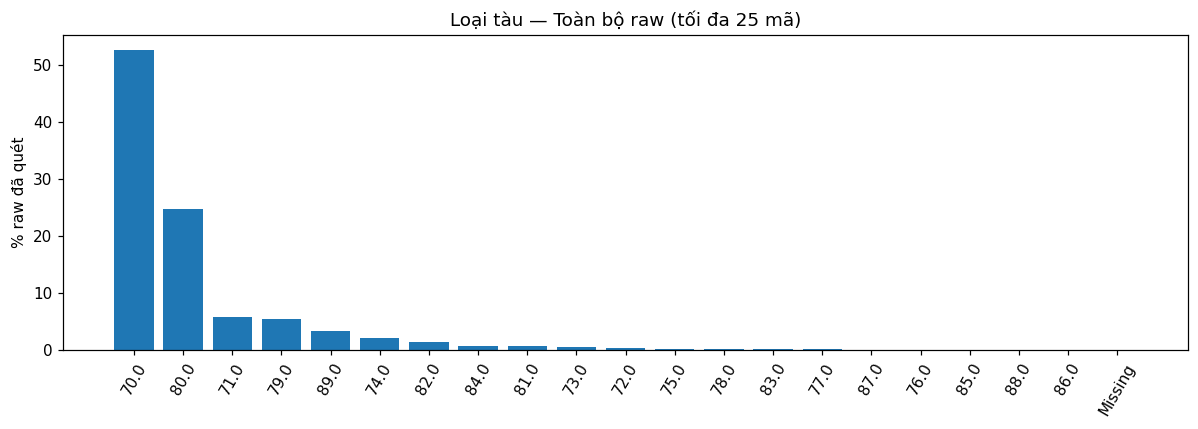

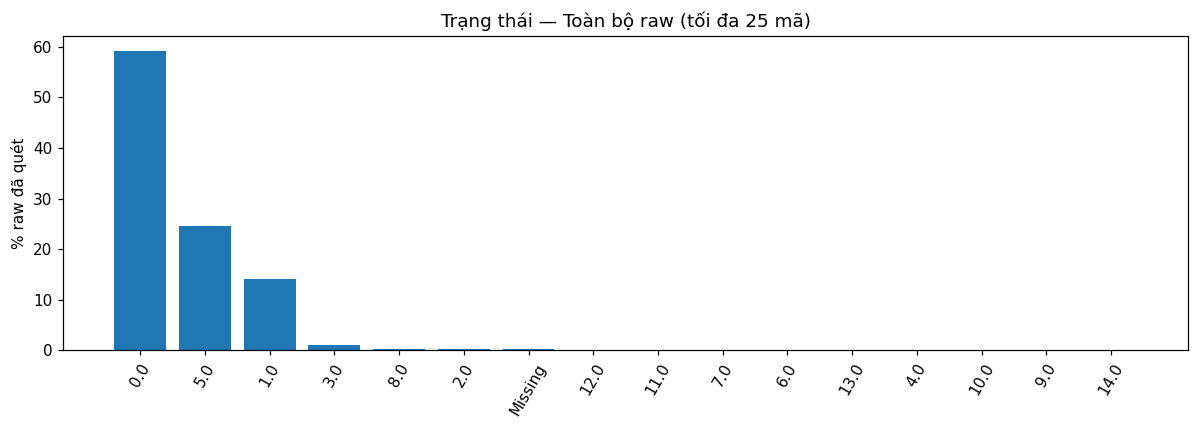

In [4]:
fig,axs=plt.subplots(1,2,figsize=(13,4))
for ax in axs: ax.stairs(hist_sog,sog_edges,fill=True,color='#2878B5'); ax.set_xlabel('SOG (knots)')
axs[0].set_xlim(0,40); axs[0].set_ylabel('Số bản ghi'); axs[0].set_title(SCOPE+' — SOG 0–40')
axs[1].set_yscale('log'); axs[1].axvline(40,color='red',ls='--'); axs[1].set_title('Phần đuôi — trục số lượng log')
save_fig(fig,RAW2/'01_sog.png')
for table,name,title in [(vessel_table,'02_vessel','Loại tàu'),(status_table,'03_status','Trạng thái')]:
    p=table.head(25)
    fig,ax=plt.subplots(figsize=(11,4)); ax.bar(p['value'].astype(str),p['pct_of_scanned_raw'])
    ax.tick_params(axis='x',rotation=60); ax.set_ylabel('% raw đã quét')
    ax.set_title(title+' — '+SCOPE+' (tối đa 25 mã)')
    save_fig(fig,RAW2/(name+'.png'))
# Sao chép các bảng đã tính; không đọc thêm dataset khác.
for df,name in [(audit,'raw_audit.csv'),(vessel_table,'vessel_types.csv'),(status_table,'status.csv')]:
    save_table(df,RAW2/name)


## A2. Mục 6.1 — mô tả nguồn gốc hai lượt
Pass 1 tạo catalog sự kiện cập bến; ghép nhãn tạo raw labeled. Notebook bắt đầu **sau** các bước này. Không kiểm chứng lại 102.050 sự kiện hoặc số dòng sạch trong tài liệu.

## A3. Mục 6.2/6.4 — tạo biến và bộ lọc trên mẫu
Haversine với bán kính phụ thuộc vĩ độ là xấp xỉ đại vòng, không phải geodesic ellipsoid chính xác. KM/NM là cùng thông tin tuyến tính (dự án đã chuẩn hóa giữ duy nhất Dist_To_Berth_NM). Area/Volume là proxy kích thước, không phải phép đo chính xác cản gió/chiếm nước.

Waterfall chưa khử trùng lặp toàn cục, chưa lọc `atd_prev`. Lọc vận tốc biểu kiến dùng target nên chỉ là lựa chọn quần thể nghiên cứu ngoại tuyến; kết quả validation chỉ áp dụng quần thể đã chọn, không đại diện vận hành raw không chọn lọc.


In [ ]:
def engineer(raw):
    d=raw.copy()
    numeric=['longitude','latitude','berth_lon','berth_lat','sog','cog','heading',
             'status','vessel_type','length','width','draft','cargo','Target_Hours']
    for c in numeric:
        d[c]=pd.to_numeric(d[c],errors='coerce').astype(float)
        d[c]=d[c].where(np.isfinite(d[c]))
    for c in ['base_date_time','ata_time']: d[c]=pd.to_datetime(d[c],errors='coerce',utc=True)
    ok=(d.latitude.between(-90,90)&d.longitude.between(-180,180)
        &d.berth_lat.between(-90,90)&d.berth_lon.between(-180,180))
    p=d.loc[ok]; lat1=np.radians(p.latitude); lat2=np.radians(p.berth_lat)
    dl=(np.radians(p.berth_lon-p.longitude)+np.pi)%(2*np.pi)-np.pi
    h=np.sin((lat2-lat1)/2)**2+np.cos(lat1)*np.cos(lat2)*np.sin(dl/2)**2
    phi=(lat1+lat2)/2; a=6378.137; b=6356.752314245
    radius=np.sqrt(((a*a*np.cos(phi))**2+(b*b*np.sin(phi))**2)/((a*np.cos(phi))**2+(b*np.sin(phi))**2))
    d['Dist_To_Berth_NM']=np.nan
    d.loc[ok,'Dist_To_Berth_NM']=2*radius*np.arcsin(np.sqrt(np.clip(h,0,1)))/1.852
    d['Area_Proxy']=d.length*d.width; d['Volume_Proxy']=d.Area_Proxy*d.draft
    d['Is_Tanker']=np.where(d.vessel_type.between(70,89),d.vessel_type.between(80,89).astype(float),np.nan)
    for c in ['cog','heading']:
        angle=np.radians(d[c].where(d[c].ge(0)&d[c].lt(360)))
        d[c+'_sin']=np.sin(angle); d[c+'_cos']=np.cos(angle)
    return d

def filter_sample(d):
    y=d.Target_Hours; dist=d.Dist_To_Berth_NM
    max_dist_nm=np.where(d.Is_Tanker.eq(1),1800.0,2300.0)
    rules=[('SOG [1,40]',d.sog.between(1,40)),
           ('Status đủ dữ liệu, khác 1/5',d.status.notna()&~d.status.isin([1,5])),
           ('Vessel type nguyên [70,89]',d.vessel_type.between(70,89)&d.vessel_type.mod(1).eq(0)),
           ('BBox theo tài liệu',d.latitude.between(15,75)&d.longitude.between(-180,-65)),
           ('Target (0,168]',y.gt(0)&y.le(168)),
           ('Khoảng cách hợp lệ <=1800 NM (Tanker) / <=2300 NM (Cargo)',dist.notna()&dist.le(max_dist_nm)),
           ('Vận tốc biểu kiến >=1.62 knots',dist.div(y.where(y>0)).ge(1.62))]
    keep=pd.Series(True,index=d.index)
    rows=[dict(step='Mẫu raw',remaining=len(d),removed_this_step=0)]
    for name,mask in rules:
        before=int(keep.sum()); keep &= mask.fillna(False); after=int(keep.sum())
        rows.append(dict(step=name,remaining=after,removed_this_step=before-after))
    return d.loc[keep].copy(),pd.DataFrame(rows)

derived=engineer(sample)
work,waterfall=filter_sample(derived)
save_table(waterfall,RAW2/'sample_filter_waterfall.csv')
display(waterfall)
if work.empty: raise ValueError('Mẫu sau lọc rỗng. Kiểm tra schema/phạm vi hoặc tăng SAMPLE_SIZE.')


## A4. Mục 6.3 — điền khuyết và mask-and-recover
Ưu tiên RAW2: chuyến → tàu → loại tàu → nhóm Cargo/Tanker; thêm fallback trung vị toàn cục nếu cần. Không hard-code kích thước mẫu từ tài liệu.

Học lookup từ tháng 1–6 (nhãn đã hoàn tất trước 1/7), kiểm chứng tháng 7–9 (nhãn hoàn tất trước 1/10). Che ngẫu nhiên 20% giá trị vốn hợp lệ, so với trung vị toàn cục. Đây là thử nghiệm thiếu ngẫu nhiên, không đại diện mọi cơ chế thiếu thực tế. Lookup chuyến có thể không áp dụng được khi chuyến giữa hai tập không giao nhau; bảng nguồn sẽ thể hiện điều đó. Trong vận hành, lookup theo chuyến/tàu chỉ dùng dữ liệu quá khứ.


In [6]:
BODY=['length','width','draft']
LEVELS=[('trip',['mmsi','trip_id']),('vessel',['mmsi']),('type',['vessel_type']),('group',['_ship_group'])]
JAN=pd.Timestamp('2025-01-01',tz='UTC'); JUL=pd.Timestamp('2025-07-01',tz='UTC'); OCT=pd.Timestamp('2025-10-01',tz='UTC')

def prepare_body(df):
    d=df.copy()
    for c in BODY:
        ok=np.isfinite(d[c])&d[c].gt(0)
        if c=='draft': ok &= d[c].le(25.5)
        d[c]=d[c].where(ok)
    d['_ship_group']=pd.Series(pd.NA,index=d.index,dtype='string')
    d.loc[d.vessel_type.between(70,79),'_ship_group']='Cargo'
    d.loc[d.vessel_type.between(80,89),'_ship_group']='Tanker'
    return d

def fit_imputer(ref):
    ref=prepare_body(ref)
    return {c:{'global':ref[c].median(), 'maps':[(name,keys,ref.groupby(keys,dropna=True)[c].median())
            for name,keys in LEVELS]} for c in BODY}

def transform_imputer(data,lookup):
    d=prepare_body(data)
    for c in BODY:
        source=pd.Series('observed',index=d.index); source.loc[d[c].isna()]='unresolved'
        for name,keys,table in lookup[c]['maps']:
            if len(keys)==1: fill=d[keys[0]].map(table)
            else:
                idx=pd.MultiIndex.from_frame(d[keys]); fill=pd.Series(table.reindex(idx).to_numpy(),index=d.index)
            take=d[c].isna()&fill.notna(); d.loc[take,c]=fill.loc[take]; source.loc[take]=name
        take=d[c].isna()
        if pd.notna(lookup[c]['global']): d.loc[take,c]=lookup[c]['global']; source.loc[take]='global'
        d[c+'_source']=source
    d['Area_Proxy']=d.length*d.width; d['Volume_Proxy']=d.Area_Proxy*d.draft
    return d

train=work.loc[work.base_date_time.ge(JAN)&work.base_date_time.lt(JUL)&work.ata_time.lt(JUL)].copy()
valid=work.loc[work.base_date_time.ge(JUL)&work.base_date_time.lt(OCT)&work.ata_time.lt(OCT)].copy()
train=train.dropna(subset=['mmsi','trip_id']); valid=valid.dropna(subset=['mmsi','trip_id'])
tr_keys=pd.MultiIndex.from_frame(train[['mmsi','trip_id']]); va_keys=pd.MultiIndex.from_frame(valid[['mmsi','trip_id']])
train=train.loc[~tr_keys.isin(va_keys)].copy()
if len(train)<100 or len(valid)<100:
    raise ValueError('Không đủ mẫu train/validation. Dùng scan toàn năm và tăng SAMPLE_SIZE.')
print('Train:',len(train),'Validation:',len(valid),'| Q4 không sử dụng')
lookup=fit_imputer(train); truth=prepare_body(valid); masked=truth.copy()
rng=np.random.default_rng(SEED+1); masks={}
for c in BODY:
    eligible=truth.index[truth[c].notna()].to_numpy()
    masks[c]=rng.choice(eligible,size=max(1,int(.2*len(eligible))),replace=False) if len(eligible) else np.array([],dtype=int)
    masked.loc[masks[c],c]=np.nan
recovered=transform_imputer(masked,lookup)
rows=[]; sources=[]
for c in BODY:
    idx=masks[c]; actual=truth.loc[idx,c].to_numpy(float); pred=recovered.loc[idx,c].to_numpy(float)
    ok=np.isfinite(actual)&np.isfinite(pred); e=pred[ok]-actual[ok]
    rows.append(dict(variable=c,N_masked=len(idx),N_recovered=int(ok.sum()),
        coverage_pct=100*ok.mean() if len(ok) else np.nan,
        MAE=np.mean(abs(e)) if len(e) else np.nan,RMSE=np.sqrt(np.mean(e**2)) if len(e) else np.nan,
        global_median_MAE=np.mean(abs(actual-lookup[c]['global'])) if len(actual) else np.nan))
    for name,n in recovered.loc[idx,c+'_source'].value_counts().items():
        sources.append(dict(variable=c,source=name,count=int(n)))
mask_results=pd.DataFrame(rows); mask_sources=pd.DataFrame(sources)
save_table(mask_results,RAW2/'table_6_1_mask_recover.csv'); save_table(mask_sources,RAW2/'mask_recover_sources.csv')
display(mask_results); display(mask_sources)


Train: 39170 Validation: 21818 | Q4 không sử dụng


,variable,N_masked,N_recovered,coverage_pct,MAE,RMSE,global_median_MAE
0,length,4347,4347,100.0,7.090177,24.012501,52.102599
1,width,4307,4307,100.0,1.139772,3.819317,6.439749
2,draft,4343,4343,100.0,1.123601,1.662427,1.956413


,variable,source,count
0,length,vessel,3515
1,length,type,832
2,width,vessel,3435
3,width,type,872
4,draft,vessel,3484
5,draft,type,859


# B. TASK 03 — Mục 6.5 và 6.6
## B1. Target lệch phải
Moments tính trên raw đã quét, phân vị/skewness trên mẫu. Histogram log1p chỉ phục vụ hiển thị, không đổi target huấn luyện. Không dùng số Mean=41,24/Median=25,59 trong mẫu tài liệu để mô tả raw. Cửa sổ (0,168] là phạm vi lựa chọn, không phải đặc tính raw.

Không oversample/undersample để cân bằng target. Phân nhóm cự ly [0,50,200,500,∞) là ngưỡng thiết kế, giữ cố định trước khi xem Q4.


In [ ]:
quant=[]
for c in moments.variable:
    x=pd.to_numeric(sample[c],errors='coerce'); x=x[np.isfinite(x)]
    quant.append(dict(variable=c,N_sample=len(x),Q1_est=x.quantile(.25),Median_est=x.median(),
                      Q3_est=x.quantile(.75),P95_est=x.quantile(.95),P99_est=x.quantile(.99),Skew_est=x.skew()))
descriptive=moments.merge(pd.DataFrame(quant),on='variable')
save_table(descriptive,TASK03/'raw_descriptive_moments_and_sample_quantiles.csv')
display(descriptive)
y=pd.to_numeric(sample.Target_Hours,errors='coerce'); y=y[np.isfinite(y)&(y>=0)]
fig,axs=plt.subplots(1,2,figsize=(13,4))
axs[0].hist(np.log1p(y),bins=80,color='#2878B5'); axs[0].set_xlabel('log(1 + Target_Hours)')
axs[0].set_title('Target raw không âm — mẫu'); axs[0].set_ylabel('Số dòng mẫu')
axs[1].stairs(hist_target,y_edges,fill=True,color='#D95319'); axs[1].set_xlabel('Target_Hours')
axs[1].set_title(SCOPE+' — phần trong [0,168]'); axs[1].set_ylabel('Số dòng raw đã quét')
save_fig(fig,TASK03/'01_target_distribution.png')
DIST_BINS=[0,25,100,250,np.inf]; DIST_LABELS=['0-25 NM','25-100 NM','100-250 NM','>250 NM']
work['distance_group']=pd.cut(work.Dist_To_Berth_NM,bins=DIST_BINS,labels=DIST_LABELS,include_lowest=True)
distance_summary=work.groupby('distance_group',observed=True).Target_Hours.agg(N='size',Mean='mean',Median='median',Max='max').reset_index()
save_table(distance_summary,TASK03/'sample_target_by_distance.csv'); display(distance_summary)


## B2. Hybrid Feature Selection, không PCA
1. Chọn biến theo tri thức miền, không dùng ATA/target/ID làm X.
2. Pearson |r|>0,85: đề xuất giảm biến theo thứ tự ưu tiên khai báo, không phải luật bắt buộc xóa mọi cặp.
3. Gain và validation: so sánh tập ban đầu/tập giảm biến. Gain không là quan hệ nhân quả.

Để tránh điền median toàn chuyến ngược thời gian trong train, thử nghiệm LightGBM này dùng khả năng xử lý NaN trực tiếp; bài kiểm chứng điền khuyết A4 là thực nghiệm riêng. Không tuyên bố mô hình đã chạy trên dữ liệu điền khuyết toàn bộ.

PCA không được dùng để giữ diễn giải trực tiếp và vì phương sai đầu vào không đồng nhất với giá trị dự báo. Không khẳng định PCA hoàn toàn không thể giải thích.


,feature_1,feature_2,pearson_r,N_pairwise
0,length,width,0.868762,38940
1,length,Area_Proxy,0.952733,38940
2,length,Volume_Proxy,0.903988,38744
3,width,Area_Proxy,0.946320,38940
4,width,Volume_Proxy,0.891055,38744
5,Area_Proxy,Volume_Proxy,0.961708,38744
6,cog_sin,heading_sin,0.962890,38881
7,cog_cos,heading_cos,0.959942,38881


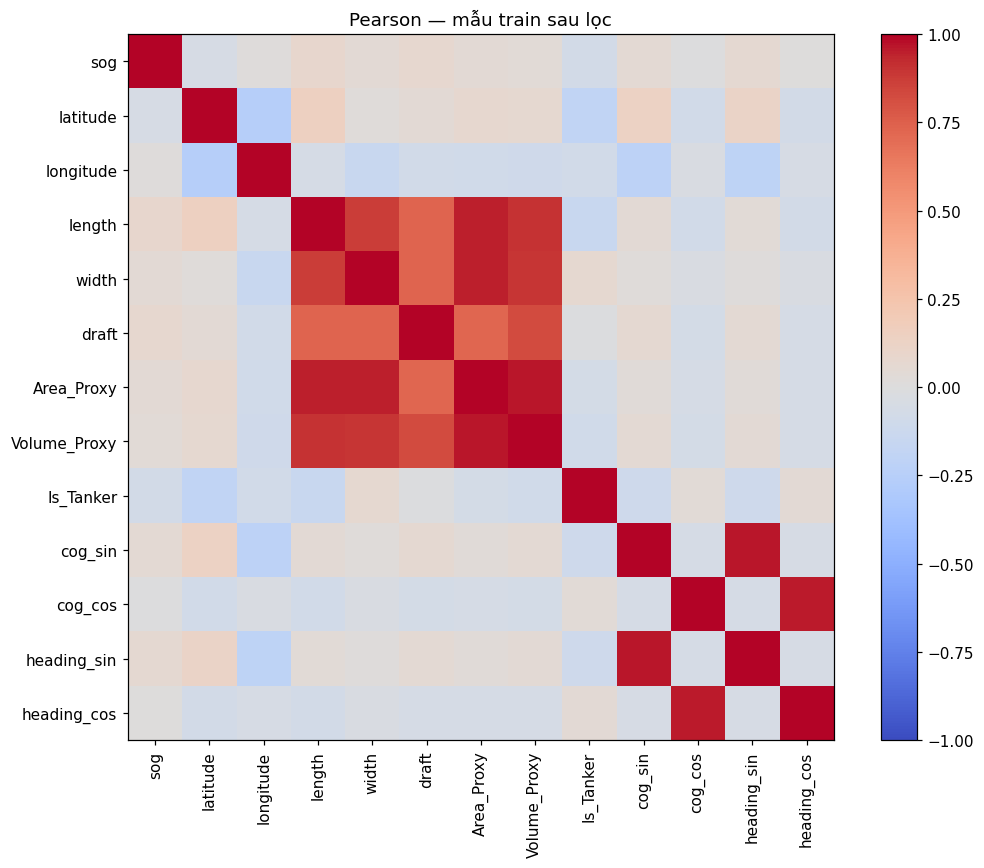

In [8]:
train=prepare_body(train); valid=prepare_body(valid)
for d in [train,valid]:
    d['Area_Proxy']=d.length*d.width; d['Volume_Proxy']=d.Area_Proxy*d.draft
features=['sog','latitude','longitude','length','width','draft','Area_Proxy','Volume_Proxy',
          'Is_Tanker','cog_sin','cog_cos','heading_sin','heading_cos']
if KNOWN_DESTINATION_AT_PREDICTION: features += ['Dist_To_Berth_NM']
features=[c for c in features if train[c].nunique(dropna=True)>1]
assert features, 'Không có biến biến thiên trong train'
correlation=train[features].corr(min_periods=100)
correlation.to_csv(TASK03/'train_pearson.csv',encoding='utf-8-sig')
pairs=[]
for i,a in enumerate(features):
    for b in features[i+1:]:
        r=correlation.loc[a,b]
        if pd.notna(r) and abs(r)>.85:
            pairs.append(dict(feature_1=a,feature_2=b,pearson_r=r,
                              N_pairwise=int(train[[a,b]].notna().all(axis=1).sum())))
pairs=pd.DataFrame(pairs,columns=['feature_1','feature_2','pearson_r','N_pairwise'])
save_table(pairs,TASK03/'high_correlation_pairs.csv'); display(pairs)
reduced=[]; drops=[]
for c in features:
    conflict=next((k for k in reduced if pd.notna(correlation.loc[c,k]) and abs(correlation.loc[c,k])>.85),None)
    if conflict is None: reduced.append(c)
    else: drops.append(dict(removed=c,retained=conflict,r=correlation.loc[c,conflict]))
save_table(pd.DataFrame(drops,columns=['removed','retained','r']),TASK03/'proposed_feature_removals.csv')
fig,ax=plt.subplots(figsize=(10,8)); im=ax.imshow(correlation,vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(len(features))); ax.set_xticklabels(features,rotation=90)
ax.set_yticks(range(len(features))); ax.set_yticklabels(features)
ax.set_title('Pearson — mẫu train sau lọc'); fig.colorbar(im,ax=ax)
save_fig(fig,TASK03/'02_pearson.png')


,model,n_features,best_iteration,MAE_hours,RMSE_hours,bias_hours,overprediction_pct
0,domain_features,13,797,17.360648,24.949986,1.801863,64.694289
1,pearson_reduced,8,800,17.426751,24.998055,1.888282,65.652214


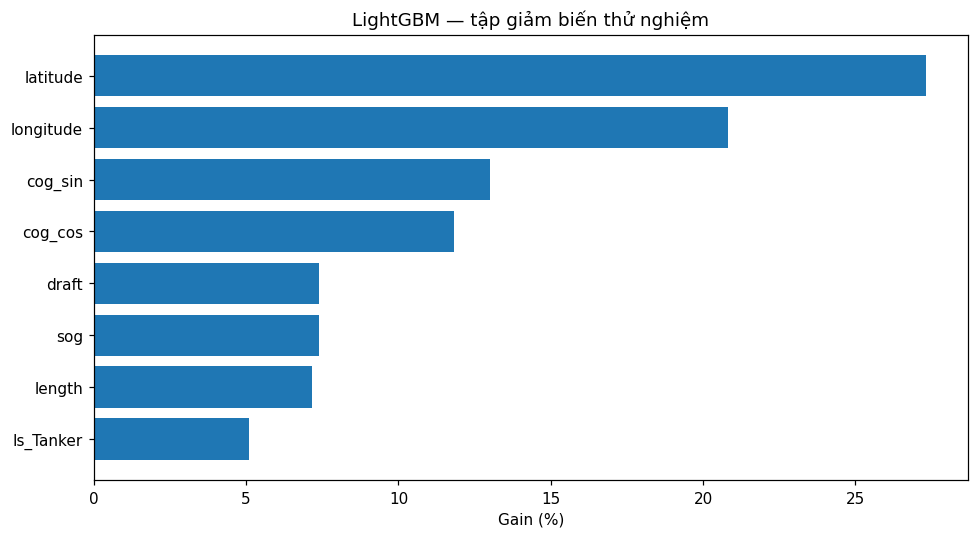

In [9]:
def metrics(y,p):
    e=np.asarray(p)-np.asarray(y)
    return dict(MAE_hours=float(np.mean(abs(e))),RMSE_hours=float(np.sqrt(np.mean(e**2))),
                bias_hours=float(np.mean(e)),overprediction_pct=float(100*np.mean(e>0)))

def fit_lgb(cols,objective='regression'):
    model=lgb.LGBMRegressor(objective=objective,n_estimators=N_ESTIMATORS,learning_rate=.05,
            num_leaves=31,reg_lambda=1.,random_state=SEED,n_jobs=N_JOBS,verbosity=-1)
    model.fit(train[cols],train.Target_Hours,eval_set=[(valid[cols],valid.Target_Hours)],
              eval_metric='l1',callbacks=[lgb.early_stopping(50,first_metric_only=True,verbose=False),lgb.log_evaluation(0)])
    return model

models={}; comparison=[]; group_results=[]
for name,cols in [('domain_features',features),('pearson_reduced',reduced)]:
    model=fit_lgb(cols); pred=model.predict(valid[cols])
    models[name]=(model,cols)
    comparison.append(dict(model=name,n_features=len(cols),best_iteration=model.best_iteration_,**metrics(valid.Target_Hours,pred)))
    gain=model.booster_.feature_importance(importance_type='gain')
    importance=pd.DataFrame(dict(feature=cols,gain=gain,gain_pct=100*gain/max(float(gain.sum()),1e-12))).sort_values('gain',ascending=False)
    save_table(importance,TASK03/('gain_'+name+'.csv'))
    model.booster_.save_model(str(TASK03/('model_'+name+'.txt')))
    groups=pd.cut(valid.Dist_To_Berth_NM,DIST_BINS,labels=DIST_LABELS,include_lowest=True)
    for group in DIST_LABELS:
        take=(groups==group).to_numpy()
        if take.any(): group_results.append(dict(model=name,distance_group=group,N=int(take.sum()),**metrics(valid.Target_Hours.to_numpy()[take],pred[take])))
comparison=pd.DataFrame(comparison); save_table(comparison,TASK03/'feature_selection_validation.csv')
save_table(pd.DataFrame(group_results),TASK03/'validation_by_distance.csv'); display(comparison)
importance=pd.read_csv(TASK03/'gain_pearson_reduced.csv').sort_values('gain_pct')
fig,ax=plt.subplots(figsize=(9,5)); ax.barh(importance.feature,importance.gain_pct)
ax.set_xlabel('Gain (%)'); ax.set_title('LightGBM — tập giảm biến thử nghiệm')
save_fig(fig,TASK03/'03_gain.png')


## B3. Thử nghiệm bổ sung: asymmetric loss
Với $e=\hat y-y$, $L=(1+\alpha)e^2$ khi $e<0$ (dự báo sớm, gây trống cầu bến), còn lại $L=e^2$.
Gradient $2we$, Hessian $2w$, với $w=1+\alpha$ khi $e<0$, còn lại 1 (chọn nhánh này tại 0).
Thử $\alpha=0; 0{,}5; 1; 1{,}5$ (mức $\alpha=1{,}5$ tương ứng trọng số phạt sớm $2{,}5\times$). Đánh giá mọi cấu hình trên cùng chỉ số `early_cost_weight_2_5` theo MAE validation; đây là thăm dò validation, không là kết luận test.

In [10]:
asym_table = pd.DataFrame()
if RUN_ASYMMETRIC_EXPERIMENT:
    rows = []

    def make_early_objective(alpha):
        """Create L2 loss penalizing early predictions (e < 0)."""
        def early_objective(y_true, y_pred):
            error = y_pred - y_true
            weight = np.where(error < 0.0, 1.0 + alpha, 1.0)
            return 2.0 * weight * error, 2.0 * weight
        return early_objective

    for alpha in [0.0, 0.5, 1.0, 1.5]:
        model = fit_lgb(reduced, make_early_objective(alpha))
        pred = model.predict(valid[reduced])
        error = pred - valid.Target_Hours.to_numpy()
        rows.append(dict(
            alpha=alpha,
            early_weight=1.0 + alpha,
            best_iteration=model.best_iteration_,
            **metrics(valid.Target_Hours, pred),
            underprediction_pct=float(100.0 * np.mean(error < 0.0)),
            early_cost_weight_2_5=float(
                np.mean(np.where(error < 0.0, 2.5, 1.0) * error ** 2)
            ),
        ))
    asym_table = pd.DataFrame(rows)
    save_table(asym_table, TASK03 / "asymmetric_loss_validation.csv")
    display(asym_table)
else:
    (TASK03 / "asymmetric_loss_validation.csv").unlink(missing_ok=True)
    print(
        "Bỏ qua thử nghiệm loss theo cấu hình; chỉ trình bày phương pháp."
    )

,alpha,MAE_hours,RMSE_hours,bias_hours,overprediction_pct,asym_cost_eval_alpha_1
0,0.0,17.402345,24.991383,1.859168,65.280961,871.023184
1,0.5,16.620220,24.865030,-0.940231,60.839674,800.160084
2,1.0,16.260408,25.069418,-2.938423,57.168393,772.303551


# C. Xuất kết quả và bàn giao
- **RAW2 / Mục 5.4:** SOG, loại tàu, trạng thái, bảng audit. Đỉnh SOG=0 không tự chứng minh lỗi sensor.
- **RAW2 / Mục 6.1:** mô tả nguồn gốc hai lượt, không ghi là notebook đã tái chạy.
- **RAW2 / Mục 6.2:** waterfall trên mẫu, nêu thiếu dedup toàn cục và atd_prev.
- **RAW2 / Mục 6.3:** Bảng 6.1 và tỷ lệ sử dụng từng cấp; 100% coverage không là 100% chính xác.
- **RAW2 / Mục 6.4:** công thức và định nghĩa các đặc trưng.
- **Task 03 / Mục 6.5:** thống kê target, phân nhóm cự ly, giải thích loss.
- **Task 03 / Mục 6.6:** Pearson, Gain, so sánh validation, lý do không PCA.
- RAW2 kế thừa kết quả 6.5–6.6 từ Task 03, không viết hai kết luận mâu thuẫn.

Không lấy số dòng trên mẫu nhân lên để gọi là số dòng sạch đo chính xác. Không ghi MAE mẫu là kết quả Q4 hoặc kết quả toàn bộ dữ liệu.


In [11]:
manifest=dict(input=str(raw_path),scope=SCOPE,sample_rows=len(sample),filtered_sample_rows=len(work),
              train_rows=len(train),validation_rows=len(valid),known_destination=KNOWN_DESTINATION_AT_PREDICTION,
              features=features,reduced_features=reduced,scan_config=scan_config,
              versions=dict(python=platform.python_version(),pandas=pd.__version__,numpy=np.__version__,lightgbm=lgb.__version__),
              limitations=['No global dedup','No atd_prev','No catalog reconstruction','No final Q4 evaluation',
                           'Target-based cohort filtering: offline research only','Imputation experiment separate from model experiment'])
(OUT/'run_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
readme=f"""KẾT QUẢ TASK03 & RAW2
Phạm vi: {SCOPE}
Input: {raw_path}
Mẫu raw: {len(sample):,}; mẫu sau lọc: {len(work):,}
Train: {len(train):,}; validation: {len(valid):,}; không đánh giá Q4.
RAW2: Mục 5.4, 6.1–6.4. TASK03: Mục 6.5–6.6.
Moments/counts trên raw đã quét; quantiles/skewness trên mẫu.
Không tái tạo đầy đủ pipeline gốc: thiếu atd_prev, dedup toàn cục và catalog nguồn.
Đọc markdown notebook để diễn giải bảng đúng phạm vi.
"""
(OUT/'README_results.txt').write_text(readme,encoding='utf-8')
zip_path=OUT.parent/'task03_raw02_results.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for path in sorted(OUT.rglob('*')):
        if path.is_file() and path.suffix!='.parquet':
            z.write(path,path.relative_to(OUT))
print('Đã lưu kết quả:',OUT)
print('ZIP không chứa mẫu parquet để gọn; mẫu vẫn nằm trong COMMON.')
display(FileLink(str(zip_path)))


Đã lưu kết quả: /kaggle/working/task03_raw02
ZIP không chứa mẫu parquet để gọn; mẫu vẫn nằm trong COMMON.


/kaggle/working/task03_raw02_results.zip